<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/unifor-logo.png" width="400">
<br>
<b>
<font size="6" face="arial" color="blue">
    Graduação em Ciência da Computação
</font>
</b>
<br>
<b>
<font size="4" face="arial">
    Disciplina: Métodos Quantitativos em Computação
</font>
</b>

**Orientador: Prof. Me. Ricardo Carubbi** <br>
*Docente da Graduação e Pós-Graduação em Ciência de Dados e Inteligência Artificial*<br>
*Laboratório de Ciência de Dados e Inteligência Artificial*<br>
*Universidade de Fortaleza*<br>

Lattes: http://lattes.cnpq.br/5738786447903616 |
GitHub: https://github.com/carubbi/

[Unifor.br](https://unifor.br/) | [Instagram](https://www.instagram.com/uniforcomunica/?hl=pt-br) | [Facebook](https://www.facebook.com/uniforoficial/) | [Twitter](https://www.facebook.com/uniforoficial/)  | [LinkedIn](https://www.linkedin.com/school/university-of-fortaleza/?originalSubdomain=pt) | [TV Unifor](https://www.unifor.br/tv-unifor) | [G1/Ensinando e Aprendendo](https://g1.globo.com/ce/ceara/especial-publicitario/unifor/ensinando-e-aprendendo/)

# AP2 — Auditoria de modelos probabilísticos

## Contexto

Na AP1, cada grupo preparou e explorou o conjunto de dados de imóveis residenciais. Nesta etapa, o professor atribuirá uma variável ou um evento e um modelo probabilístico candidato. O grupo deverá confrontar o modelo com os dados, verificar seus pressupostos e emitir um parecer fundamentado sobre sua adequação.

A finalidade não é confirmar o modelo atribuído. Um parecer de inadequação será válido quando sustentado pelo tipo da variável, pelo suporte, pelo mecanismo probabilístico, pelos resultados observados e pela simulação.

## Pergunta de pesquisa

O modelo probabilístico atribuído é adequado para representar o comportamento da variável ou do evento analisado?

## Objetivo da investigação

Avaliar criticamente a adequação de um modelo Binomial, de Poisson ou Normal a partir dos dados observados no Ames Housing, confrontando-os com as propriedades teóricas e os pressupostos do modelo atribuído.

## Atribuição da investigação

O professor atribuirá a cada grupo:

- uma variável ou um evento do conjunto de dados;
- um modelo candidato entre Binomial, Poisson e Normal.

A atribuição será registrada antes da análise e não poderá ser substituída em razão dos resultados encontrados.

### Trilha Binomial

O professor definirá um evento binário, como:

- presença de lareira, `Fireplaces > 0`;
- presença de revestimento de alvenaria, `Mas Vnr Area > 0`;
- registro de reforma, `Year Remod/Add > Year Built`.

O grupo representará o número de ocorrências do evento em $n=20$ seleções sob o modelo Binomial.

### Trilha Poisson

O professor indicará uma contagem discreta não negativa, como:

- número de lareiras (`Fireplaces`);
- capacidade da garagem (`Garage Cars`);
- número de banheiros (`Full Bath`);
- número de quartos (`Bedroom AbvGr`).

Essas variáveis são contagens limitadas por características do imóvel e não correspondem necessariamente a ocorrências em um intervalo. Essa possível incompatibilidade integra a auditoria e não deverá ser omitida.

### Trilha Normal

O professor indicará uma variável quantitativa contínua, como:

- preço de venda (`SalePrice`);
- área construída (`Gr Liv Area`);
- área do lote (`Lot Area`).

O grupo deverá examinar localização, dispersão, simetria, caudas e valores discrepantes. O histograma e o Q–Q plot serão obrigatórios e deverão ser interpretados conjuntamente. A distribuição Normal não poderá ser escolhida ou aceita apenas pela aparência do histograma nem pelo alinhamento parcial dos pontos no Q–Q plot.

## Carregamento dos dados

Uma célula de código exclusiva deverá carregar `data/processed/AmesHousing.csv`, produzido na AP1. O Ames Housing será a única base de dados da AP2. Poderão ser realizadas verificações mínimas de dimensões, tipos e valores ausentes da variável atribuída. A limpeza geral e as decisões registradas na AP1 não serão redefinidas.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Raiz do repositório: funciona executando a partir da raiz ou de notebooks/.
RAIZ = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
caminho_processado = RAIZ / "data/processed/AmesHousing.csv"
dados = pd.read_csv(caminho_processado)
dados.shape

(2927, 83)

## Etapas obrigatórias

### 1. Delimitação da variável aleatória

O grupo deverá:

- identificar a unidade de análise;
- descrever em linguagem natural a variável ou o evento atribuído;
- definir a variável aleatória e seus valores possíveis;
- classificá-la como discreta ou contínua;
- indicar seu suporte observado e o suporte previsto pelo modelo;
- formular a pergunta específica da investigação.

#### 1.1 Variável e modelo analisados

- **Trilha:** Normal.
- **Variável:** preço de venda (`SalePrice`).

A escolha dá continuidade à AP1, cuja pergunta de pesquisa tratou da distribuição e da variabilidade dos preços de venda. A variável e o modelo ficam registrados aqui antes de qualquer análise e não serão trocados em função dos resultados.

#### 1.2 Unidade de análise e definição da variável aleatória

- **Unidade de análise:** um imóvel residencial vendido em Ames (Iowa, EUA) entre 2006 e 2010; cada linha da base processada corresponde a uma venda (chave `PID`).
- **Descrição em linguagem natural:** valor, em dólares americanos, pelo qual o imóvel foi vendido.
- **Variável aleatória:** $X$ = preço de venda, em US\$, de um imóvel selecionado ao acaso entre as vendas registradas na base processada.
- **Valores possíveis:** conceitualmente, qualquer valor monetário positivo, $X \in (0, +\infty)$.

A verificação abaixo confirma a presença, o tipo e a escala de registro da variável na base produzida pela AP1.

In [2]:
preco = dados["SalePrice"]

pd.Series(
    {
        "tipo computacional": preco.dtype,
        "registros": len(preco),
        "valores distintos": preco.nunique(),
        "valores não inteiros": int((preco % 1 != 0).sum()),
        "mínimo observado (US$)": preco.min(),
        "máximo observado (US$)": preco.max(),
    },
    name="SalePrice",
).to_frame()

,SalePrice
tipo computacional,int64
registros,2927
valores distintos,1030
valores não inteiros,0
mínimo observado (US$),12789
máximo observado (US$),755000


#### 1.3 Classificação e suporte

- **Classificação:** variável **quantitativa contínua**. O preço é uma grandeza monetária que, em princípio, pode assumir qualquer valor positivo; o registro em dólares inteiros (nenhum valor não inteiro e mais de mil valores distintos) é apenas um arredondamento de medida e não torna a variável discreta para fins de modelagem.
- **Suporte observado:** $[12.789;\ 755.000]$ US\$, sempre estritamente positivo.
- **Suporte natural da variável:** $(0, +\infty)$; não existe preço negativo ou nulo em uma venda efetiva.
- **Suporte previsto pelo modelo Normal:** $(-\infty, +\infty)$, isto é, o modelo atribui probabilidade positiva a preços negativos, ainda que possivelmente pequena.

#### 1.4 Pergunta específica da investigação

> O modelo $\mathrm{Normal}(\mu, \sigma^2)$, calibrado com a média e o desvio-padrão observados, representa de forma adequada a distribuição dos preços de venda (`SalePrice`) dos imóveis residenciais de Ames, em particular sua localização, dispersão, simetria e caudas?

A divergência entre o suporte natural $(0, +\infty)$ e o suporte do modelo $(-\infty, +\infty)$ é o primeiro ponto de atenção e será levada para a análise de compatibilidade a seguir.

### 2. Compatibilidade inicial do modelo atribuído

Antes de realizar os cálculos e as simulações, o grupo deverá confrontar o modelo atribuído com:

- o tipo da variável;
- o suporte;
- o mecanismo probabilístico;
- os parâmetros;
- os pressupostos essenciais.

A compatibilidade inicial deverá ser apresentada de forma sintética antes de qualquer comparação gráfica. Ela orientará a auditoria, mas não antecipará o parecer final.

O quadro a seguir confronta, antes de qualquer cálculo de probabilidades ou simulação, as exigências do modelo Normal com o que se sabe da variável preço de venda. A coluna *situação inicial* indica apenas a expectativa que orientará a auditoria; o parecer final depende das evidências empíricas e simuladas das próximas etapas.

In [3]:
compatibilidade = pd.DataFrame(
    [
        ["Tipo da variável",
         "Quantitativa contínua",
         "Preço é quantitativo contínuo (registrado em US$ inteiros)",
         "Compatível"],
        ["Suporte",
         "(-∞, +∞)",
         "(0, +∞); observado em [12.789; 755.000]",
         "Parcialmente compatível"],
        ["Mecanismo probabilístico",
         "Soma de muitos efeitos pequenos, independentes e aditivos",
         "Preço resulta de fatores que tendem a agir de forma multiplicativa (área, qualidade, localização)",
         "Duvidoso"],
        ["Parâmetros",
         "μ (localização) e σ (dispersão), sem parâmetro de forma",
         "Calibráveis pela média e pelo desvio-padrão observados",
         "Compatível"],
        ["Pressupostos essenciais",
         "Simetria em torno de μ, caudas leves, média = mediana",
         "Preços costumam ter assimetria à direita e cauda superior longa",
         "A verificar (expectativa desfavorável)"],
    ],
    columns=["Aspecto", "Exigência do modelo Normal", "Característica da variável", "Situação inicial"],
).set_index("Aspecto")
compatibilidade

,Exigência do modelo Normal,Característica da variável,Situação inicial
Aspecto,,,
Tipo da variável,Quantitativa contínua,Preço é quantitativo contínuo (registrado em U...,Compatível
Suporte,"(-∞, +∞)","(0, +∞); observado em [12.789; 755.000]",Parcialmente compatível
Mecanismo probabilístico,"Soma de muitos efeitos pequenos, independentes...",Preço resulta de fatores que tendem a agir de ...,Duvidoso
Parâmetros,"μ (localização) e σ (dispersão), sem parâmetro...",Calibráveis pela média e pelo desvio-padrão ob...,Compatível
Pressupostos essenciais,"Simetria em torno de μ, caudas leves, média = ...",Preços costumam ter assimetria à direita e cau...,A verificar (expectativa desfavorável)


**Síntese da compatibilidade inicial.**

- **Tipo e parâmetros** não impõem obstáculos: o preço é contínuo e o modelo precisa apenas de $\mu$ e $\sigma$, que podem ser calibrados diretamente pelos dados.
- **Suporte** é uma incompatibilidade estrutural: o modelo admite preços negativos, enquanto a variável é limitada inferiormente por zero. A gravidade dependerá de quanta probabilidade o modelo calibrado coloca abaixo de zero, o que será quantificado nas etapas 4 a 6.
- **Mecanismo** é o ponto conceitual mais frágil: a Normal surge naturalmente da soma de muitos efeitos aditivos, mas o preço de um imóvel tende a combinar fatores de forma proporcional (um bairro valorizado eleva o preço em percentual, não em valor fixo), o que costuma gerar assimetria à direita.
- **Pressupostos de simetria e caudas** precisarão ser examinados na descrição empírica, com histograma e Q–Q plot interpretados em conjunto.

Assim, a auditoria parte de uma compatibilidade **parcial**: o modelo é aplicável em termos de tipo e parâmetros, mas há razões conceituais para esperar desvios na forma e nas caudas. A próxima etapa verifica se os dados confirmam ou afastam essa expectativa.

### 3. Descrição empírica

O grupo deverá apresentar:

- quantidade de observações válidas e valores ausentes;
- tabela de frequências relativas para variável discreta ou medidas descritivas para variável contínua;
- representação gráfica coerente com o tipo da variável;
- média e variância observadas;
- características relevantes para a auditoria, como concentração, assimetria, caudas, excesso de zeros ou limites naturais.

O gráfico deverá possuir título, eixos, unidades e interpretação. Não serão exigidas visualizações redundantes.

Na trilha Normal, a descrição empírica deverá incluir um histograma e um Q–Q plot. A interpretação do Q–Q plot deverá distinguir o alinhamento na região central de desvios nas caudas e de observações discrepantes.

#### 3.1 Observações válidas e valores ausentes

Na AP1, `SalePrice` não exigiu imputação; aqui apenas se confirma quantas observações estão disponíveis para a auditoria.

In [4]:
n_total = len(preco)
n_ausentes = int(preco.isna().sum())
n_validos = int(preco.notna().sum())
x = preco.dropna()

pd.Series(
    {"registros na base": n_total, "observações válidas": n_validos, "valores ausentes": n_ausentes},
    name="SalePrice",
).to_frame()

,SalePrice
registros na base,2927
observações válidas,2927
valores ausentes,0


Todas as 2.927 vendas da base processada possuem preço registrado, sem valores ausentes. A auditoria utilizará, portanto, o conjunto completo de observações produzido pela AP1, sem nova exclusão.

#### 3.2 Medidas descritivas

Para uma variável contínua, a descrição empírica é feita por medidas de posição, dispersão e forma. Incluem-se também as cercas de Tukey, já empregadas na AP1, para dimensionar os valores discrepantes que afetarão a auditoria das caudas.

In [5]:
q1, mediana, q3 = x.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
li_tukey, ls_tukey = q1 - 1.5 * iqr, q3 + 1.5 * iqr

media_obs = x.mean()
var_obs = x.var()          # variância amostral (ddof=1)
dp_obs = x.std()

medidas = pd.Series(
    {
        "n": len(x),
        "média (US$)": media_obs,
        "mediana (US$)": mediana,
        "variância (US$²)": var_obs,
        "desvio-padrão (US$)": dp_obs,
        "coeficiente de variação (%)": 100 * dp_obs / media_obs,
        "mínimo (US$)": x.min(),
        "Q1 (US$)": q1,
        "Q3 (US$)": q3,
        "máximo (US$)": x.max(),
        "IQR (US$)": iqr,
        "assimetria": x.skew(),
        "curtose em excesso": x.kurt(),
        "limite inferior de Tukey (US$)": li_tukey,
        "limite superior de Tukey (US$)": ls_tukey,
        "discrepantes abaixo de LI": int((x < li_tukey).sum()),
        "discrepantes acima de LS": int((x > ls_tukey).sum()),
    },
    name="SalePrice",
)
medidas.to_frame().style.format("{:,.2f}")

,SalePrice
n,"2,927.00"
média (US$),"180,800.77"
mediana (US$),"160,000.00"
variância (US$²),"6,388,270,543.09"
desvio-padrão (US$),"79,926.66"
coeficiente de variação (%),44.21
mínimo (US$),"12,789.00"
Q1 (US$),"129,500.00"
Q3 (US$),"213,500.00"
máximo (US$),"755,000.00"


**Interpretação das medidas.**

- **Localização:** a média (≈ US\$ 180.801) supera a mediana (US\$ 160.000) em cerca de US\$ 20.800. Em uma distribuição Normal, média e mediana coincidem; a diferença indica que valores altos puxam a média para cima.
- **Dispersão:** o desvio-padrão (≈ US\$ 79.927, variância ≈ $6{,}39 \times 10^{9}$ US\$²) corresponde a um coeficiente de variação de cerca de 44%, uma variabilidade elevada para preços.
- **Simetria:** a assimetria de ≈ 1,74 é claramente positiva (a Normal tem assimetria 0), confirmando cauda à direita mais longa.
- **Caudas:** a curtose em excesso de ≈ 5,11 (a Normal tem 0) indica caudas mais pesadas e mais concentração no centro do que o modelo prevê.
- **Valores discrepantes:** pelas cercas de Tukey, há 137 vendas acima de US\$ 339.500 e nenhuma abaixo do limite inferior (US\$ 3.500). Os discrepantes estão todos de um mesmo lado, o que reforça a assimetria; segundo as decisões da AP1, eles são vendas legítimas e permanecem na base.
- **Limite natural:** o menor preço (US\$ 12.789) está a pouco mais de 2 desvios-padrão abaixo da média, mas a variável não pode ultrapassar zero; o lado esquerdo é, portanto, comprimido por um limite natural, enquanto o direito se estende até US\$ 755.000 (cerca de 7 desvios-padrão acima da média).

#### 3.3 Histograma e Q–Q plot

Na trilha Normal, o histograma e o Q–Q plot são obrigatórios e devem ser lidos em conjunto: o histograma mostra a forma global da distribuição, e o Q–Q plot compara cada quantil observado com o quantil que uma Normal de mesma média e desvio-padrão produziria.

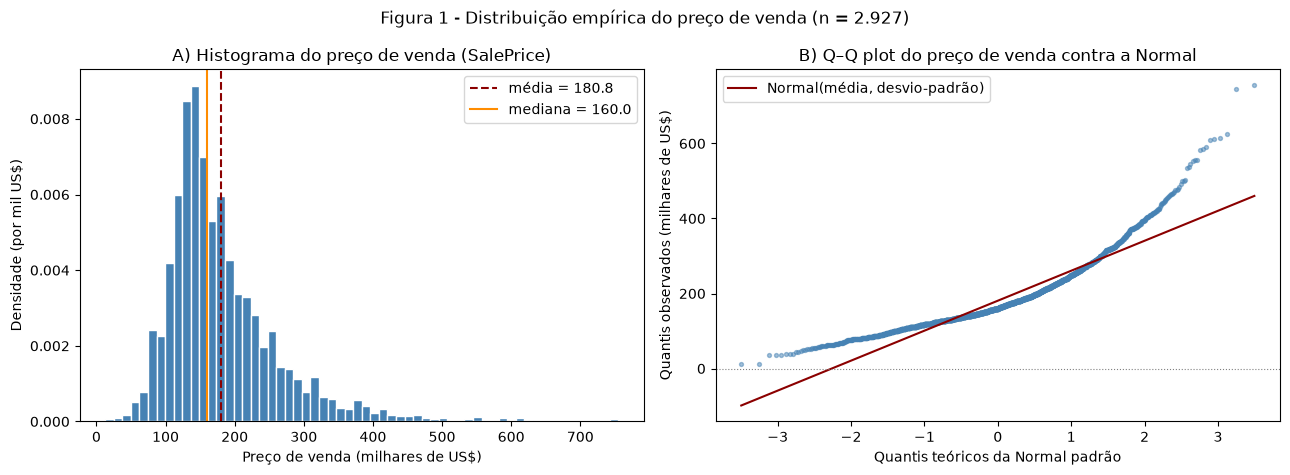

In [6]:
fig, (ax_hist, ax_qq) = plt.subplots(1, 2, figsize=(13, 4.8))

# Painel A - histograma em densidade, com média e mediana.
ax_hist.hist(x / 1000, bins=60, density=True, color="steelblue", edgecolor="white")
ax_hist.axvline(media_obs / 1000, color="darkred", linestyle="--", label=f"média = {media_obs / 1000:,.1f}")
ax_hist.axvline(mediana / 1000, color="darkorange", linestyle="-", label=f"mediana = {mediana / 1000:,.1f}")
ax_hist.set_title("A) Histograma do preço de venda (SalePrice)")
ax_hist.set_xlabel("Preço de venda (milhares de US$)")
ax_hist.set_ylabel("Densidade (por mil US$)")
ax_hist.legend()

# Painel B - Q-Q plot contra a Normal, com a reta de referência ajustada pela média e pelo desvio-padrão.
(teoricos, ordenados), _ = stats.probplot(x, dist="norm")
ax_qq.scatter(teoricos, ordenados / 1000, s=8, alpha=0.5, color="steelblue")
referencia = (media_obs + dp_obs * teoricos) / 1000
ax_qq.plot(teoricos, referencia, color="darkred", label="Normal(média, desvio-padrão)")
ax_qq.axhline(0, color="gray", linewidth=0.8, linestyle=":")
ax_qq.set_title("B) Q–Q plot do preço de venda contra a Normal")
ax_qq.set_xlabel("Quantis teóricos da Normal padrão")
ax_qq.set_ylabel("Quantis observados (milhares de US$)")
ax_qq.legend()

fig.suptitle("Figura 1 - Distribuição empírica do preço de venda (n = 2.927)")
fig.tight_layout()
plt.show()

**Interpretação conjunta do histograma e do Q–Q plot.**

- **Histograma (painel A):** a distribuição é unimodal, com o pico entre US\$ 130 mil e US\$ 160 mil, mas nitidamente assimétrica: o lado esquerdo cai rapidamente em direção ao limite natural de zero, enquanto o lado direito se prolonga numa cauda longa até US\$ 755 mil. A mediana fica à esquerda da média, coerente com a assimetria positiva medida.
- **Região central do Q–Q plot (painel B):** os pontos cruzam a reta de referência perto de −1 e de +1,2 quantis teóricos e, entre esses dois cruzamentos, ficam ligeiramente **abaixo** dela: os preços centrais são um pouco menores do que a Normal de mesma média preveria, reflexo de a mediana (US\$ 160 mil) ser inferior à média. O alinhamento no centro é, portanto, apenas aproximado e já mostra a curvatura convexa que se acentua nas caudas.
- **Cauda inferior:** à esquerda, os pontos ficam **acima** da reta: os menores preços observados são maiores do que a Normal preveria. A cauda esquerda é mais curta que a do modelo, efeito do limite natural em zero. A reta de referência chega a valores negativos, mostrando que o modelo projeta preços impossíveis nessa região.
- **Cauda superior:** à direita, os pontos se afastam fortemente **para cima** da reta: os maiores preços são muito superiores aos quantis normais correspondentes. É a assinatura gráfica de uma cauda direita pesada.
- **Observações discrepantes:** os poucos pontos isolados acima de US\$ 600 mil, no extremo superior direito, são as vendas mais caras da base. Eles acentuam o desvio, mas a curvatura da cauda superior já começa bem antes deles (por volta de US\$ 300 mil), portanto o afastamento da Normal não se deve apenas a alguns casos extremos.

O alinhamento parcial na região central não basta para aceitar o modelo: o padrão em forma de curva (cauda esquerda curta e cauda direita longa) é sistemático e típico de uma distribuição com assimetria positiva.

#### 3.4 Concentração em torno da média

Uma forma complementar de examinar concentração e caudas é comparar a proporção de preços observados nos intervalos $\bar{x} \pm k\,s$ com a regra empírica da Normal (68,27%, 95,45% e 99,73%), separando as caudas esquerda e direita.

In [7]:
linhas = []
for k in (1, 2, 3):
    inferior, superior = media_obs - k * dp_obs, media_obs + k * dp_obs
    linhas.append(
        {
            "k": k,
            "intervalo (US$)": f"[{inferior:,.0f}; {superior:,.0f}]",
            "observado dentro (%)": 100 * x.between(inferior, superior).mean(),
            "Normal dentro (%)": 100 * (stats.norm.cdf(k) - stats.norm.cdf(-k)),
            "observado abaixo (%)": 100 * (x < inferior).mean(),
            "observado acima (%)": 100 * (x > superior).mean(),
            "Normal em cada cauda (%)": 100 * stats.norm.cdf(-k),
        }
    )

pd.DataFrame(linhas).set_index("k").round(2)

,intervalo (US$),observado dentro (%),Normal dentro (%),observado abaixo (%),observado acima (%),Normal em cada cauda (%)
k,,,,,,
1,"[100,874; 260,727]",78.27,68.27,8.64,13.09,15.87
2,"[20,947; 340,654]",95.35,95.45,0.07,4.58,2.28
3,"[-58,979; 420,581]",98.46,99.73,0.00,1.54,0.13


**Interpretação.**

- Dentro de $\bar{x} \pm 1s$ estão cerca de 78% dos preços, contra 68% previstos pela Normal: há **mais concentração no centro** do que o modelo admite, coerente com a curtose em excesso positiva.
- Em $\bar{x} \pm 2s$ e $\bar{x} \pm 3s$ as proporções totais (≈ 95,4% e ≈ 98,5%) parecem próximas das teóricas, mas a divisão entre as caudas revela o problema: praticamente nenhuma venda fica abaixo de $\bar{x} - 2s$ (≈ 0,07% contra 2,28% previstos), enquanto cerca de 4,6% ficam acima de $\bar{x} + 2s$, o dobro do previsto. Acima de $\bar{x} + 3s$ estão ≈ 1,5% das vendas, mais de dez vezes o 0,13% da Normal.
- O intervalo $\bar{x} \pm 3s$ já começa em um valor negativo (≈ −US\$ 59 mil), outra manifestação da incompatibilidade de suporte apontada na etapa 2.
- Proporções totais semelhantes escondem, portanto, uma compensação entre uma cauda esquerda quase vazia e uma cauda direita pesada.

#### Conclusão parcial da descrição empírica

Os dados descrevem uma variável contínua, positiva e sem ausências, mas com **assimetria positiva acentuada**, **caudas mais pesadas que as da Normal**, **concentração central excessiva** e um **limite natural em zero** que encurta a cauda esquerda. O histograma, o Q–Q plot e as proporções por intervalo convergem para a mesma leitura e confirmam a expectativa desfavorável levantada na compatibilidade inicial quanto à simetria e às caudas. Essas características não encerram a auditoria: a próxima etapa calibra formalmente o modelo $\mathrm{Normal}(\mu, \sigma^2)$, e a simulação permitirá verificar se os desvios observados são compatíveis com a variação esperada do próprio modelo.

### 4. Modelo candidato e parâmetros

O grupo deverá definir o modelo, seus parâmetros e suas propriedades.

#### Binomial

Definir:

$$
X\colon \mathrm{Binomial}(20,p),
\tag{2.1}
$$

em que $p$ é a frequência relativa observada do evento atribuído. Calcular e interpretar:

$$
\mathrm{E}(X)=20p
\quad\text{e}\quad
\mathrm{Var}(X)=20p(1-p).
\tag{2.2}
$$

#### Poisson

Definir:

$$
X\colon \mathrm{Poisson}(\lambda),
\tag{2.3}
$$

utilizando a média observada como calibração empírica de $\lambda$. Calcular e interpretar:

$$
\mathrm{E}(X)=\lambda
\quad\text{e}\quad
\mathrm{Var}(X)=\lambda.
\tag{2.4}
$$

A igualdade teórica entre média e variância deverá ser confrontada com os dados, sem ser tratada isoladamente como prova de adequação.

#### Normal

Definir:

$$
X\colon \mathrm{Normal}(\mu,\sigma^2),
\tag{2.5}
$$

utilizando a média e o desvio-padrão observados como calibração empírica de $\mu$ e $\sigma$. Interpretar:

$$
\mathrm{E}(X)=\mu
\quad\text{e}\quad
\mathrm{Var}(X)=\sigma^2.
\tag{2.6}
$$

Essas calibrações têm finalidade descritiva e computacional. Não serão apresentadas como inferência para uma população.

### 5. Simulação reproduzível

Gerar 10.000 realizações do modelo candidato com semente registrada. A simulação deverá utilizar os parâmetros definidos na etapa anterior e funções apropriadas do `numpy.random.Generator` ou do `scipy.stats`.

As realizações simuladas serão utilizadas como instrumento computacional para tornar as propriedades do modelo observáveis. Elas não constituirão uma segunda base de dados nem substituirão os registros do Ames Housing.

O grupo deverá comparar:

- média teórica, observada e simulada;
- variância teórica, observada e simulada;
- comportamento gráfico observado e simulado.

Para comparações gráficas entre amostras de tamanhos diferentes, deverão ser utilizadas frequências relativas ou densidades, conforme o tipo da variável.

### 6. Auditoria dos pressupostos

O grupo deverá examinar os pressupostos correspondentes à sua trilha.

#### Binomial

- número fixo de ensaios;
- dois resultados por ensaio;
- probabilidade constante;
- independência;
- interpretação das seleções no conjunto finito observado.

#### Poisson

- contagem de ocorrências;
- intervalo ou exposição bem definido;
- taxa aproximadamente constante;
- independência das ocorrências;
- ausência de limite estrutural incompatível com o suporte do modelo;
- compatibilidade entre média, variância e frequência de zeros.

#### Normal

- variável quantitativa contínua;
- suporte teórico e limites naturais da variável;
- concentração aproximadamente simétrica;
- comportamento das caudas;
- efeito de valores discrepantes;
- alinhamento e desvios observados no Q–Q plot;
- compatibilidade entre probabilidades observadas e teóricas em intervalos relevantes.

### 7. Parecer de adequação

O grupo deverá classificar o modelo como:

- **adequado:** o mecanismo, o suporte, os pressupostos e as comparações são suficientemente coerentes para a finalidade delimitada;
- **parcialmente adequado:** o modelo oferece aproximação útil, mas apresenta violações ou limitações relevantes;
- **inadequado:** o mecanismo, o suporte ou as evidências tornam seu uso indefensável para a finalidade proposta.

O parecer deverá integrar evidências conceituais, numéricas, gráficas e simuladas. Não será aceita conclusão baseada somente na semelhança visual entre distribuições.

## Delimitações

Não integram esta AP:

- distribuições Uniforme e Exponencial, pois as variáveis selecionadas do Ames Housing não representam, respectivamente, valores contínuos equiprováveis em um intervalo ou tempos de espera associados a um processo com taxa constante;
- testes formais de aderência;
- testes de normalidade;
- estimação por máxima verossimilhança;
- seleção automática de distribuições;
- transformação de variáveis com a finalidade exclusiva de obter ajuste;
- generalização dos resultados para outros mercados imobiliários.

## Conclusão

A conclusão deverá responder diretamente à pergunta de pesquisa, apresentar o parecer de adequação, identificar as evidências decisivas e reconhecer os limites do conjunto de dados e da modelagem realizada.

## Contribuições dos integrantes

## Declaração de uso de inteligência artificial

## Referências